Test MSE (normalized): 0.160402 | RMSE: 0.400502
Test MSE (original scale): 0.015508 | RMSE: 0.124531
Saved to output_sample_0.png


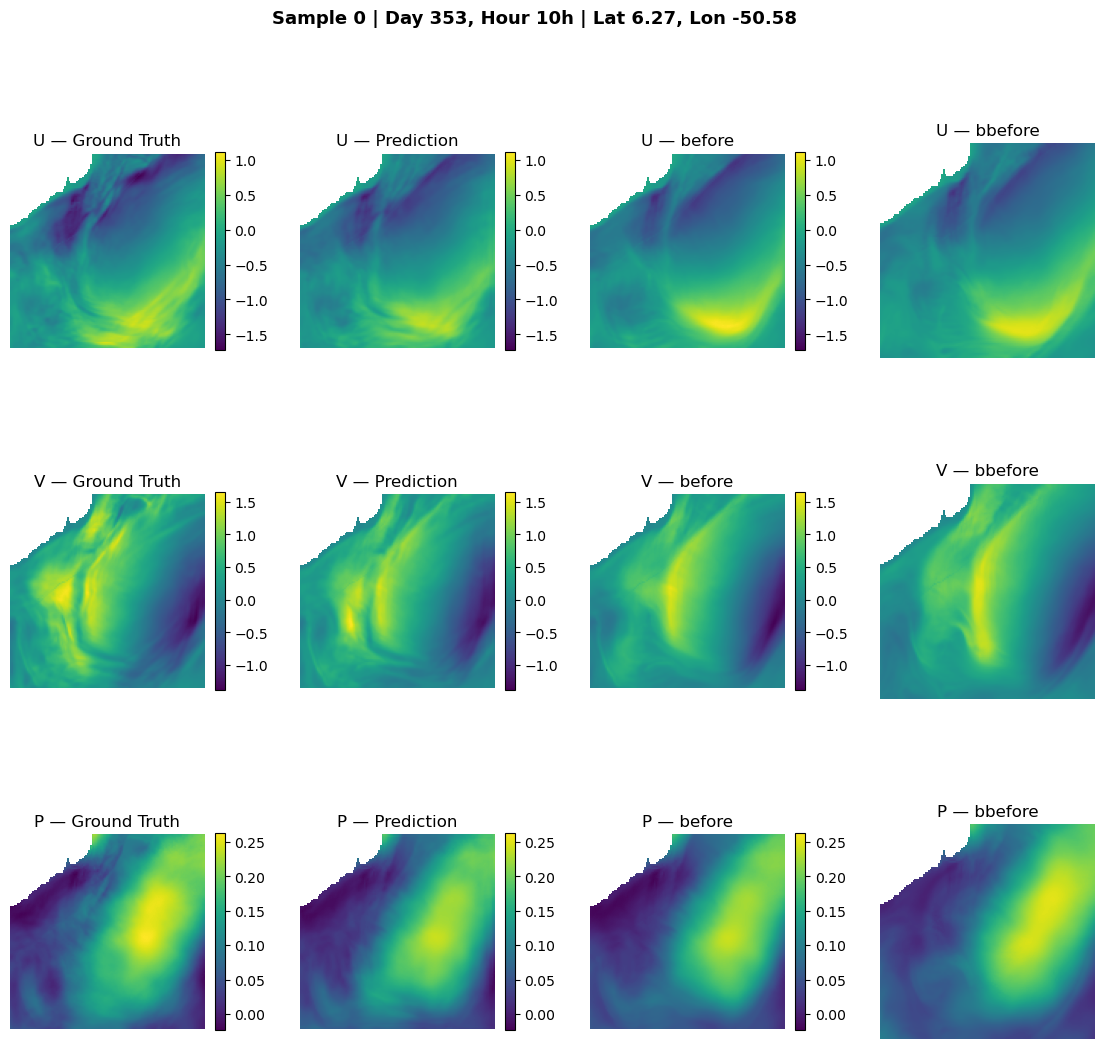

Saved to output_sample_1.png


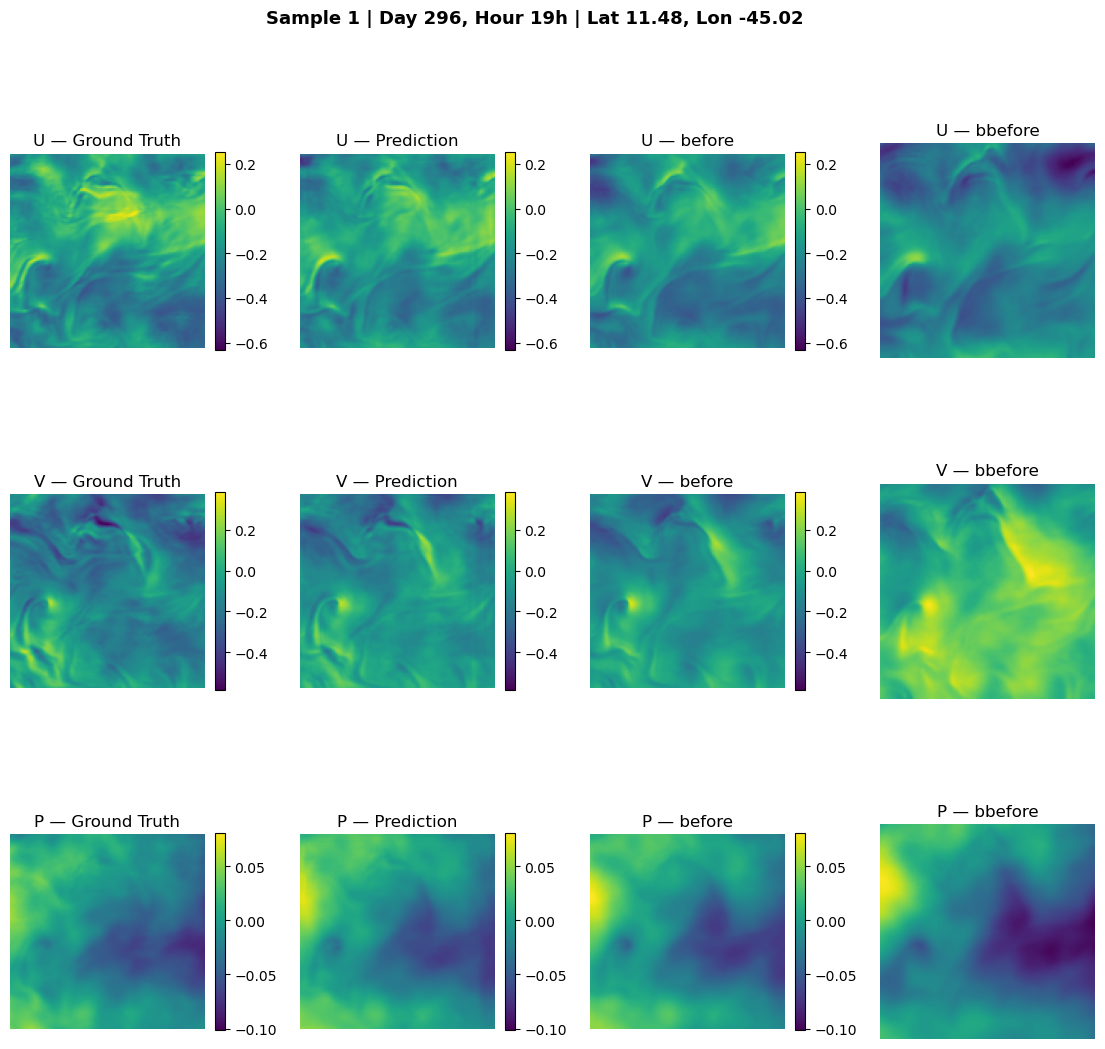

Saved to output_sample_2.png


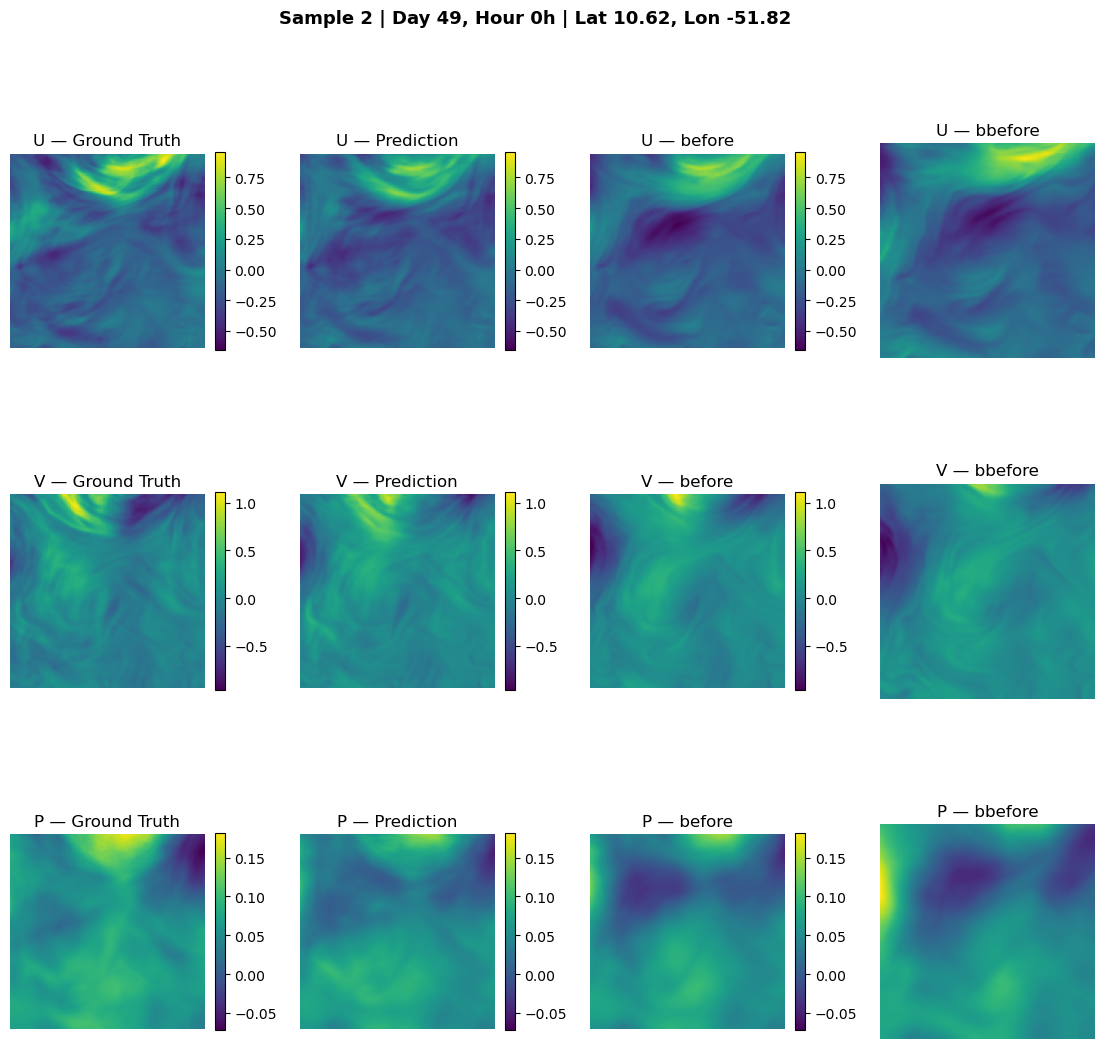

Saved to output_sample_45.png


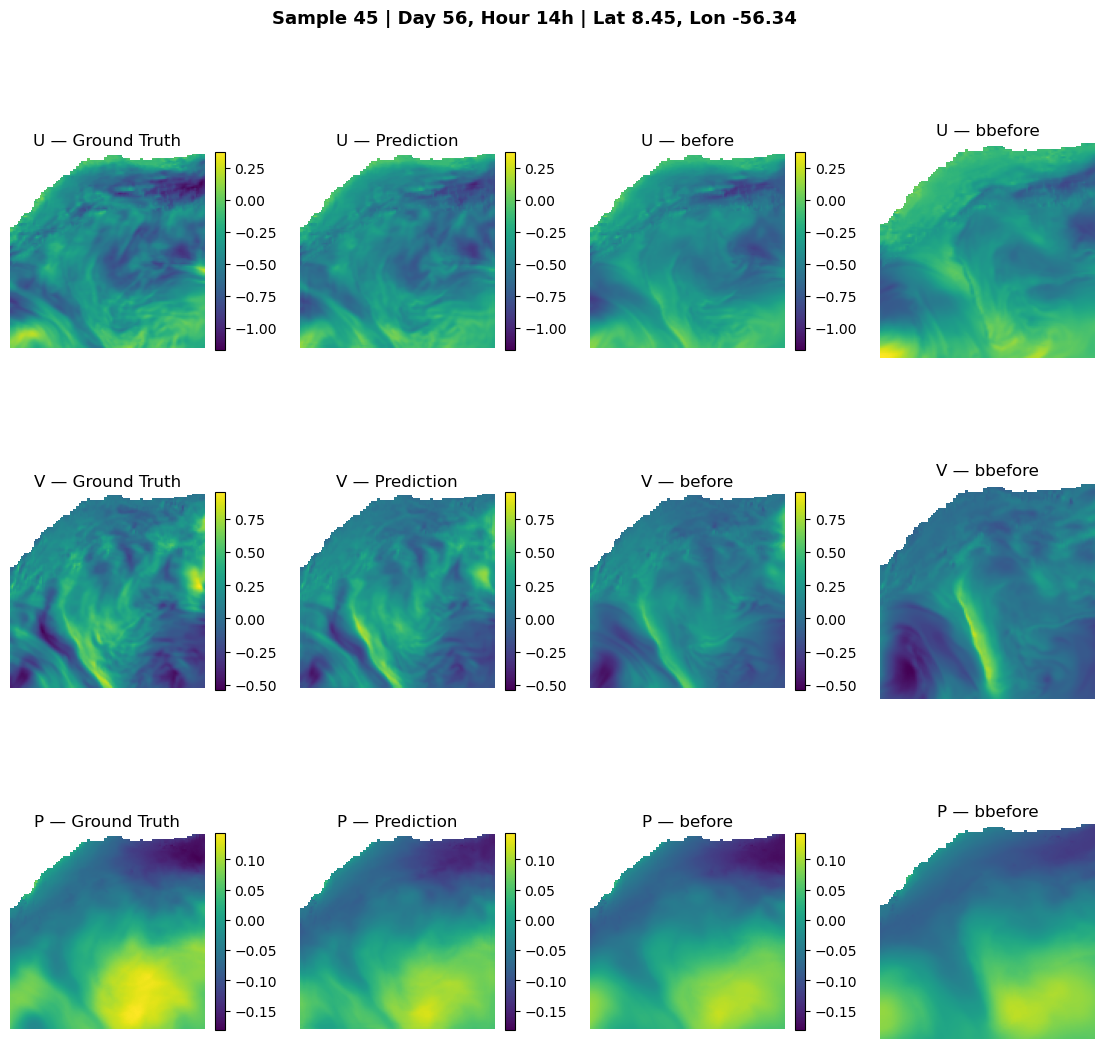

Saved to output_sample_32.png


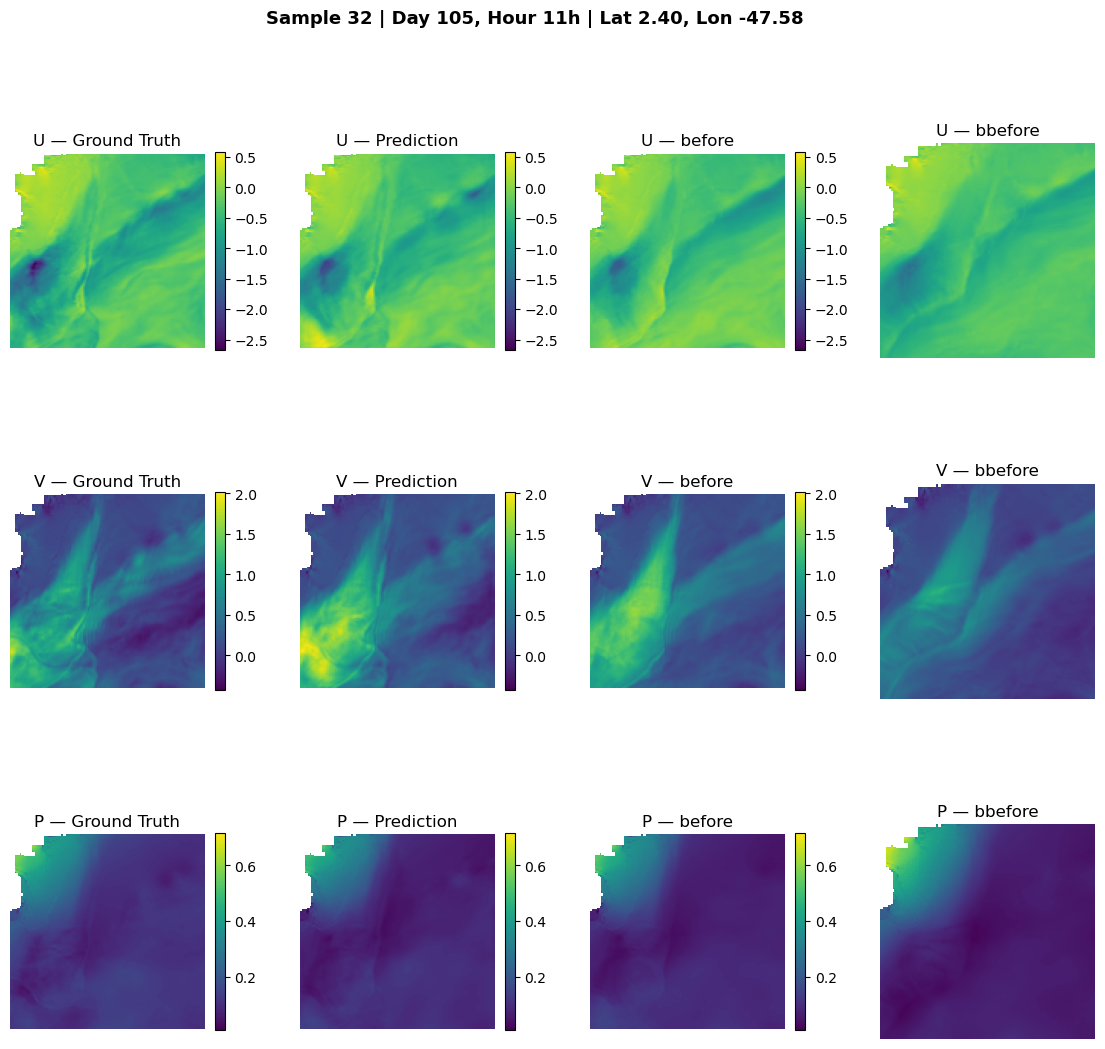

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from torch.utils.data import DataLoader
from model import DSCMS 

# ----------------------------
# Load test data
# ----------------------------
def load_test_data(
    sims_path:   str = "data/sampleY_sims.npy",
    mask_path:   str = "data/sampleY_mask.npy",
    day_path:    str = "data/sampleY_day.npy",
    hour_path:   str = "data/sampleY_hour.npy",
    latlon_path: str = "data/sampleY_latlon.npy",
    stats_path:  str = "norm_stats.pt",
    test_split:  float = 1.0,
    seed:        int = 42,
):
    sims   = torch.from_numpy(np.load(sims_path))    # [N, T, 3, H, W]
    mask   = torch.from_numpy(np.load(mask_path))    # [N, H, W]
    day    = torch.from_numpy(np.load(day_path))     # [N]
    hour   = torch.from_numpy(np.load(hour_path))    # [N]
    latlon = torch.from_numpy(np.load(latlon_path))  # [N, 2]

    N = len(sims)
    rng = np.random.default_rng(seed)
    indices = rng.permutation(N)
    n_test  = int(N * test_split)

    test_idx = indices[:n_test]

    # Load normalization stats from training
    stats = torch.load(stats_path, map_location="cpu")
    mean  = stats["mean"]   # [1, 9, 1, 1]
    std   = stats["std"]    # [1, 9, 1, 1]
    mean_x = self.mean.repeat(1, 3, 1, 1)  # [1, 9, 1, 1]
    std_x  = self.std.repeat(1, 3, 1, 1)   # [1, 9, 1, 1]

    return {
        "sims":   sims[test_idx],    # [N_test, T, 3, H, W]
        "mask":   mask[test_idx],    # [N_test, H, W]
        "day":    day[test_idx],     # [N_test]
        "hour":   hour[test_idx],    # [N_test]
        "latlon": latlon[test_idx],  # [N_test, 2]
        "mean":   mean_x,
        "std":    std_x
    }


# ----------------------------
# Inference
# ----------------------------
def run_inference(
    model:      torch.nn.Module,
    test_data:  dict,
    device:     str = "cuda" if torch.cuda.is_available() else "cpu",
    batch_size: int = 16,
):
    model = model.to(device).eval()

    sims = test_data["sims"]  # [N, T, 3, H, W]
    mean = test_data["mean"]   # [1, 9, 1, 1]
    std  = test_data["std"]    # [1, 9, 1, 1]    

    # Build inputs/targets same as training
    x = torch.cat([sims[:, 0], sims[:, 1], sims[:, 2]], dim=1).float()  # [N, 9, H, W]
    x = (x - mean) / (std + 1e-8)

    # Build and normalize y
    y_mean = mean[:, :3, :, :]   # [1, 3, 1, 1]
    y_std  = std[:, :3, :, :]    # [1, 3, 1, 1]
    y = (sims[:, 3] - sims[:, 2]).float()
    y = (y - y_mean) / (y_std + 1e-8)                                # [N, 3, H, W]

    dataset    = torch.utils.data.TensorDataset(x, y)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    preds, targets = [], []
    criterion = torch.nn.MSELoss()
    total_loss = 0.0

    with torch.no_grad():
        for x_batch, y_batch in dataloader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            pred = model(x_batch)
            total_loss += criterion(pred, y_batch).item() * x_batch.size(0)
            preds.append(pred.cpu())
            targets.append(y_batch.cpu())

    preds   = torch.cat(preds,   dim=0)   # [N, 3, H, W]
    targets = torch.cat(targets, dim=0)   # [N, 3, H, W]
    mse     = total_loss / len(dataset)

    print(f"Test MSE (normalized): {mse:.6f} | RMSE: {mse**0.5:.6f}")

    # Denormalize back to original scale for plotting
    preds_denorm   = preds   * (y_std + 1e-8) + y_mean   # [N, 3, H, W]
    targets_denorm = targets * (y_std + 1e-8) + y_mean   # [N, 3, H, W]

    mse_denorm = torch.mean((preds_denorm - targets_denorm) ** 2).item()
    print(f"Test MSE (original scale): {mse_denorm:.6f} | RMSE: {mse_denorm**0.5:.6f}")

    return sims[:, 0],sims[:, 1],preds_denorm, targets_denorm, mse_denorm


def apply_mask(field: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """Set masked regions (mask==1) to NaN so imshow skips them."""
    out = field.copy()
    out[mask == 1] = np.nan
    return out

# ----------------------------
# Plot
# ----------------------------
CHANNEL_NAMES = ["U", "V", "P"]  # adjust to your fields

def plot_sample(
    bbfore:   torch.Tensor,
    befor:    torch.Tensor,
    preds:    torch.Tensor,   # [N, 3, H, W]
    targets:  torch.Tensor,   # [N, 3, H, W]
    test_data: dict,
    sample_idx: int = 0,
    save_path:  str = None,
):
    bbfore = bbfore[sample_idx].numpy()  # [3, H, W]
    befor  = befor[sample_idx].numpy()   # [3, H
    pred   = preds[sample_idx].numpy()   + befor # [3, H, W]
    target = targets[sample_idx].numpy() + befor # [3, H, W]
    mask   = test_data["mask"][sample_idx].numpy()  # [H, W]
    day    = test_data["day"][sample_idx].item()
    hour   = test_data["hour"][sample_idx].item()
    lat, lon = test_data["latlon"][sample_idx].tolist()

    n_channels = pred.shape[0]  # 3
    fig = plt.figure(figsize=(14, 4 * n_channels))
    fig.suptitle(
        f"Sample {sample_idx} | Day {day}, Hour {hour}h | "
        f"Lat {lat:.2f}, Lon {lon:.2f}",
        fontsize=13, fontweight="bold"
    )

    gs = gridspec.GridSpec(n_channels, 4, figure=fig, wspace=0.35, hspace=0.4)

    for ch in range(n_channels):
        t = apply_mask(target[ch], mask)
        p = apply_mask(pred[ch],   mask)
        b = apply_mask(befor[ch],  mask)
        bb = apply_mask(bbfore[ch],mask)

        vmin = np.nanmin([t, p,b,bb])
        vmax = np.nanmax([t, p,b,bb])

        # vmin = min(target[ch].min(), pred[ch].min(),befor.min(),bbfore.min())
        # vmax = max(target[ch].max(), pred[ch].max(),befor.max(),bbfore.max())
        # diff = pred[ch] - target[ch]
        # clim = max(abs(diff.min()), abs(diff.max()))

        # Ground truth
        ax0 = fig.add_subplot(gs[ch, 0])
        im0 = ax0.imshow(t, vmin=vmin, vmax=vmax, cmap="viridis")
        ax0.set_title(f"{CHANNEL_NAMES[ch]} — Ground Truth")
        ax0.axis("off")
        plt.colorbar(im0, ax=ax0, fraction=0.046)

        # Prediction
        ax1 = fig.add_subplot(gs[ch, 1])
        im1 = ax1.imshow(p, vmin=vmin, vmax=vmax, cmap="viridis")
        ax1.set_title(f"{CHANNEL_NAMES[ch]} — Prediction")
        ax1.axis("off")
        plt.colorbar(im1, ax=ax1, fraction=0.046)

        # Residual (error)
        ax2 = fig.add_subplot(gs[ch, 2])
        im2 = ax2.imshow(b, vmin=vmin, vmax=vmax, cmap="viridis")
        ax2.set_title(f"{CHANNEL_NAMES[ch]} — before")
        ax2.axis("off")
        plt.colorbar(im2, ax=ax2, fraction=0.046)

        # Mask
        ax3 = fig.add_subplot(gs[ch, 3])
        ax3.imshow(bb, vmin=vmin, vmax=vmax, cmap="viridis")
        ax3.set_title(f"{CHANNEL_NAMES[ch]} — bbefore")
        ax3.axis("off")

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved to {save_path}")
    plt.show()


# ----------------------------
# Usage
# ----------------------------
model = DSCMS(in_channels=9, out_channels=3)
model.load_state_dict(torch.load("best_model.pth", map_location="cpu"))

test_data = load_test_data()
bbefor,befor,preds, targets, mse = run_inference(model, test_data)

# Plot a few samples
for i in [0, 1, 2,45,32]:
    plot_sample(bbefor,befor,preds, targets, test_data, sample_idx=i, save_path=f"output_sample_{i}.png")

In [12]:
test_data["sims"].shape

torch.Size([10, 7, 3, 128, 128])